In [ ]:
# Larger batch size and increasing the number of dim / hidden dim were somewhat obvious in terms of hyperparam tuning to improve the model, 
# but i was suprised at the LR needing to be substantively higher (~54% from .1 used in the video) to get faster convergence and better results. 
# Also interesting that the decay schedule and full training iterations was smaller than what our naive version was. There was a lot of room from improvement, 
# and it was interesting pushing the MLP to a decent limit to see how it could perform.

#results below
# Selected config: {'emb_dim': 24, 'hidden_dim': 750, 'batch_size': 256, 'lr': 0.15355887634905266}
# Validation loss: 2.06487
# Test loss: 2.05626

In [5]:
import torch
import torch.nn.functional as F
from pathlib import Path
import random
import matplotlib.pyplot as plt
import torch.nn as nn
import optuna
import pandas
%matplotlib inline

In [6]:
path = Path("names.txt")

words = path.read_text().splitlines()

print(len(words))
print(words[:10])

32033
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


In [7]:
chs = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chs)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [8]:
def b_ds(words):
    bs = 3
    x, y = [], []
    
    for w in words:
    
        context = [0] * bs
        for ch in w + '.':
            ix = stoi[ch]
            x.append(context)
            y.append(ix)
            context = context[1:] + [ix]
    
    x = torch.tensor(x)
    y = torch.tensor(y)
    return x, y


In [9]:
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

In [10]:
xtrain, ytrain = b_ds(words[:n1])
xval, yval = b_ds(words[n1:n2])
xtest, ytest = b_ds(words[n2:])

In [11]:
Xtr, Ytr = xtrain.long().to("cuda"), ytrain.long().to("cuda")
Xva, Yva = xval.long().to("cuda"), yval.long().to("cuda")

In [12]:
BLOCK = Xtr.shape[1]

In [13]:
class NameMLP(nn.Module):
    def __init__(self, emb_dim, hidden_dim):
        super().__init__()

        self.emb = nn.Embedding(27, emb_dim)
        self.fc1 = nn.Linear(BLOCK * emb_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, 27)

    def forward(self, x):
        x = self.emb(x).flatten(1)
        x = torch.tanh(self.fc1(x))
        return self.fc2(x)

In [14]:
@torch.no_grad()
def eval_loss(model, X, Y, chunk=4096):
    was_training = model.training
    model.eval()

    total = 0.0

    for start in range(0, len(Y), chunk):
        end = start + chunk
        logits = model(X[start:end])

        total += F.cross_entropy(
            logits,
            Y[start:end],
            reduction="sum"
        ).item()

    model.train(was_training)
    return total / len(Y)

In [19]:
def train_once(cfg, steps=15_000, seed=42,
               trial=None, eval_every=2000, decay_at=0.7):

    torch.manual_seed(seed)

    model = NameMLP(
        cfg["emb_dim"],
        cfg["hidden_dim"]
    ).to("cuda")

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=cfg["lr"]
    )

    batch_rng = torch.Generator(
        device="cuda"
    ).manual_seed(seed + 10_000)

    best_val = float("inf")
    best_step = 0
    best_weights = None
    history = []

    for step in range(1, steps + 1):

        if decay_at is not None and step > decay_at * steps:
            lr = cfg["lr"] * 0.1
        else:
            lr = cfg["lr"]
        optimizer.param_groups[0]["lr"] = lr

        ix = torch.randint(
            len(Xtr),
            (cfg["batch_size"],),
            generator=batch_rng,
            device="cuda"
        )

        logits = model(Xtr[ix])
        loss = F.cross_entropy(logits, Ytr[ix])

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if step % eval_every == 0 or step == steps:
            val = eval_loss(model, Xva, Yva)

            history.append((step, loss.item(), val))

            if val < best_val:
                best_val = val
                best_step = step

                best_weights = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }

            if trial is not None:
                trial.report(val, step)

                if trial.should_prune():
                    raise optuna.TrialPruned()

    return best_val, best_step, best_weights, history

In [16]:
def objective(trial):
    cfg = {
        "emb_dim": trial.suggest_categorical(
            "emb_dim", [8, 10, 16, 24, 32]
        ),
        "hidden_dim": trial.suggest_categorical(
            "hidden_dim", [100, 200, 300, 500]
        ),
        "batch_size": trial.suggest_categorical(
            "batch_size", [64, 128, 256]
        ),
        "lr": trial.suggest_float(
            "lr", 0.01, 0.3, log=True
        ),
    }

    val, step, _, _ = train_once(
        cfg,
        steps=15_000,
        seed=42,
        trial=trial
    )

    trial.set_user_attr("best_step", step)
    return val

In [176]:
study = optuna.create_study(
    study_name="makemore_mlp_v1",
    storage="sqlite:///makemore_mlp.db",
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=1234),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=4000
    )
)

study.optimize(objective, n_trials=20)

print("Best validation:", study.best_value)
print("Best config:", study.best_params)

[I 2026-11-06 17:38:43,819] Using an existing study with `study_name='makemore_mlp_v1'` instead of creating a new one.
[I 2026-11-06 17:39:07,004] Trial 3 finished with value: 2.1379986672955424 and parameters: {'emb_dim': 24, 'hidden_dim': 500, 'batch_size': 64, 'lr': 0.10222511983986288}. Best is trial 3 with value: 2.1379986672955424.
[I 2026-11-06 17:39:31,388] Trial 4 finished with value: 2.18196930220856 and parameters: {'emb_dim': 8, 'hidden_dim': 200, 'batch_size': 256, 'lr': 0.09165675979627692}. Best is trial 3 with value: 2.1379986672955424.
[I 2026-11-06 17:39:53,897] Trial 5 finished with value: 2.16040242584432 and parameters: {'emb_dim': 32, 'hidden_dim': 200, 'batch_size': 256, 'lr': 0.04498787786040385}. Best is trial 3 with value: 2.1379986672955424.
[I 2026-11-06 17:40:15,913] Trial 6 finished with value: 2.218068051564145 and parameters: {'emb_dim': 8, 'hidden_dim': 100, 'batch_size': 128, 'lr': 0.07886761889828948}. Best is trial 3 with value: 2.1379986672955424.
[

Best validation: 2.0798598637954107
Best config: {'emb_dim': 32, 'hidden_dim': 500, 'batch_size': 256, 'lr': 0.25025859708673637}


ImportError: Tried to import 'pandas' but failed. Please make sure that the package is installed correctly to use this feature. Actual error: No module named 'pandas'.

In [3]:
df

,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_emb_dim,params_hidden_dim,params_lr,user_attrs_best_step,system_attrs_tpe:relative_params:0,state
0,0,NaN,2026-11-06 17:34:57.010853,2026-11-06 17:35:01.809801,0 days 00:00:04.798948,64,24,500,0.102225,NaN,NaN,FAIL
1,1,NaN,2026-11-06 17:36:09.929710,2026-11-06 17:36:10.073970,0 days 00:00:00.144260,64,24,500,0.102225,NaN,NaN,FAIL
2,2,NaN,2026-11-06 17:37:16.539690,2026-11-06 17:37:16.841186,0 days 00:00:00.301496,64,24,500,0.102225,NaN,NaN,FAIL
3,3,2.137999,2026-11-06 17:38:43.835492,2026-11-06 17:39:06.962436,0 days 00:00:23.126944,64,24,500,0.102225,15000.0,NaN,COMPLETE
4,4,2.181969,2026-11-06 17:39:07.010102,2026-11-06 17:39:31.370666,0 days 00:00:24.360564,256,8,200,0.091657,15000.0,NaN,COMPLETE
5,5,2.160402,2026-11-06 17:39:31.392189,2026-11-06 17:39:53.867432,0 days 00:00:22.475243,256,32,200,0.044988,15000.0,NaN,COMPLETE
6,6,2.218068,2026-11-06 17:39:53.902141,2026-11-06 17:40:15.884071,0 days 00:00:21.981930,128,8,100,0.078868,15000.0,NaN,COMPLETE
7,7,2.204192,2026-11-06 17:40:15.917819,2026-11-06 17:40:36.857688,0 days 00:00:20.939869,64,24,100,0.036705,14000.0,NaN,COMPLETE
8,8,2.189462,2026-11-06 17:40:36.887070,2026-11-06 17:40:53.036936,0 days 00:00:16.149866,128,16,100,0.061875,NaN,NaN,PRUNED
9,9,2.301859,2026-11-06 17:40:53.066510,2026-11-06 17:40:58.746317,0 days 00:00:05.679807,64,32,500,0.016802,NaN,NaN,PRUNED


In [17]:
cfg = study.best_params

val, best_step, weights, history = train_once(
    cfg,
    steps=60_000,
    seed=42,
    eval_every=2000
)

print(f"Best validation loss: {val:.5f}")
print(f"Best step: {best_step}")

Best validation loss: 2.07025
Best step: 50000


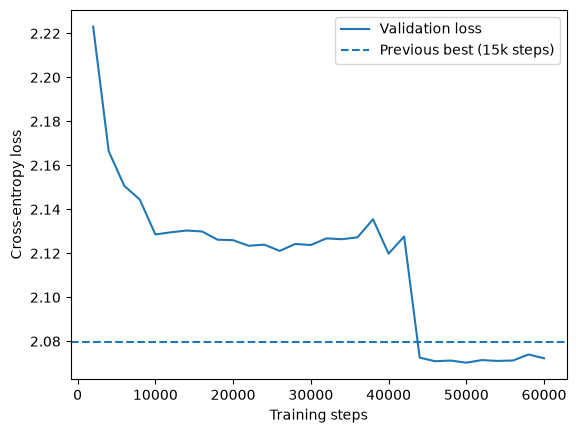

In [18]:
steps, train_losses, val_losses = zip(*history)

plt.plot(steps, val_losses, label="Validation loss")
plt.axhline(
    study.best_value,
    linestyle="--",
    label="Previous best (15k steps)"
)

plt.xlabel("Training steps")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

In [20]:
cfg = study.best_params

schedules = {
    "Decay at 20k": 20_000 / 60_000,
    "Decay at 30k": 30_000 / 60_000,
    "Decay at 42k": 42_000 / 60_000,
    "No decay": None
}

results = {}

for name, decay_at in schedules.items():
    val, best_step, weights, history = train_once(
        cfg,
        steps=60_000,
        seed=42,
        eval_every=2000,
        decay_at=decay_at
    )

    results[name] = {
        "val": val,
        "best_step": best_step,
        "history": history,
        "weights": weights
    }

    print(f"{name}: {val:.5f} at step {best_step}")

Decay at 20k: 2.06680 at step 26000
Decay at 30k: 2.06822 at step 34000
Decay at 42k: 2.07025 at step 50000
No decay: 2.11982 at step 40000


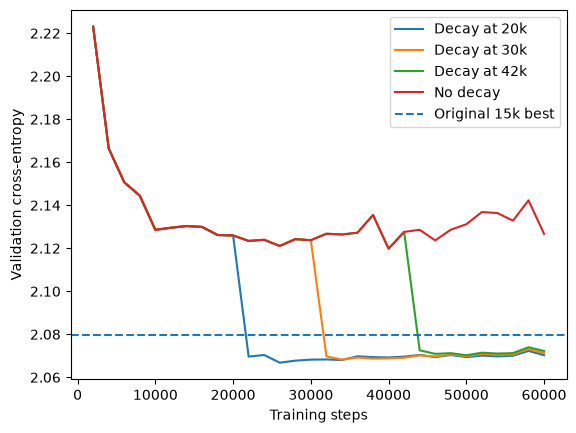

In [21]:
import matplotlib.pyplot as plt

for name, result in results.items():
    steps, train_losses, val_losses = zip(
        *result["history"]
    )

    plt.plot(steps, val_losses, label=name)

plt.axhline(
    study.best_value,
    linestyle="--",
    label="Original 15k best"
)

plt.xlabel("Training steps")
plt.ylabel("Validation cross-entropy")
plt.legend()
plt.show()

In [22]:
import pandas as pd

summary = pd.DataFrame([
    {
        "schedule": name,
        "best_val": r["val"],
        "best_step": r["best_step"]
    }
    for name, r in results.items()
])

display(summary.sort_values("best_val"))

,schedule,best_val,best_step
0,Decay at 20k,2.066797,26000
1,Decay at 30k,2.068221,34000
2,Decay at 42k,2.070250,50000
3,No decay,2.119818,40000


In [23]:
for decay_step in [5_000, 10_000, 15_000]:
    val, best_step, weights, history = train_once(
        cfg,
        steps=60_000,
        seed=42,
        eval_every=2000,
        decay_at=decay_step / 60_000
    )

    print(decay_step, val, best_step)

5000 2.0765932331477335 60000
10000 2.0727034565267526 54000
15000 2.069347413096062 26000


In [24]:
records = []

for seed in [42, 123, 999]:
    for decay_step in [15_000, 20_000, 30_000]:

        val, best_step, _, _ = train_once(
            cfg,
            steps=60_000,
            seed=seed,
            eval_every=2000,
            decay_at=decay_step / 60_000
        )

        records.append({
            "seed": seed,
            "decay_step": decay_step,
            "best_val": val,
            "best_step": best_step
        })

seed_df = pd.DataFrame(records)

display(
    seed_df.groupby("decay_step")["best_val"]
    .agg(["mean", "std", "min", "max"])
)

,mean,std,min,max
decay_step,,,,
15000,2.070476,0.001139,2.069347,2.071625
20000,2.068262,0.001917,2.066797,2.070432
30000,2.068244,0.000176,2.068081,2.068430


In [25]:
seed_df

,seed,decay_step,best_val,best_step
0,42,15000,2.069347,26000
1,42,20000,2.066797,26000
2,42,30000,2.068221,34000
3,123,15000,2.070456,32000
4,123,20000,2.067557,32000
5,123,30000,2.068081,32000
6,999,15000,2.071625,48000
7,999,20000,2.070432,40000
8,999,30000,2.068430,40000


In [26]:
def refined_objective(trial):
    cfg = {
        "emb_dim": trial.suggest_categorical(
            "emb_dim", [16, 24, 32, 48]
        ),
        "hidden_dim": trial.suggest_categorical(
            "hidden_dim", [200, 300, 500, 750]
        ),
        "batch_size": trial.suggest_categorical(
            "batch_size", [128, 256, 512]
        ),
        "lr": trial.suggest_float(
            "lr", 0.10, 0.40, log=True
        )
    }

    val, best_step, _, _ = train_once(
        cfg,
        steps=50_000,
        seed=42,
        eval_every=2000,
        decay_at=30_000 / 50_000
    )

    trial.set_user_attr("best_step", best_step)
    return val

In [27]:
study2 = optuna.create_study(
    study_name="makemore_mlp_refined",
    storage="sqlite:///makemore_mlp.db",
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=1234)
)

study2.optimize(refined_objective, n_trials=12)

[I 2026-11-06 18:41:00,910] A new study created in RDB with name: makemore_mlp_refined
[I 2026-11-06 18:42:15,009] Trial 0 finished with value: 2.075214402743916 and parameters: {'emb_dim': 48, 'hidden_dim': 750, 'batch_size': 128, 'lr': 0.20027609778010624}. Best is trial 0 with value: 2.075214402743916.
[I 2026-11-06 18:43:30,811] Trial 1 finished with value: 2.0651555601772538 and parameters: {'emb_dim': 24, 'hidden_dim': 750, 'batch_size': 256, 'lr': 0.16674552131498413}. Best is trial 1 with value: 2.0651555601772538.
[I 2026-11-06 18:44:44,210] Trial 2 finished with value: 2.0837608904479112 and parameters: {'emb_dim': 16, 'hidden_dim': 500, 'batch_size': 128, 'lr': 0.26558296572706375}. Best is trial 1 with value: 2.0651555601772538.
[I 2026-11-06 18:45:52,545] Trial 3 finished with value: 2.079151819175837 and parameters: {'emb_dim': 24, 'hidden_dim': 750, 'batch_size': 128, 'lr': 0.21777919859464642}. Best is trial 1 with value: 2.0651555601772538.
[I 2026-11-06 18:47:04,027] 

In [28]:
# final model. forgot to save it, but this is the best cfg i found in a reasonable amount of time
cfg = study2.best_params.copy()

print("Selected config:", cfg)
print(
    "Original best step:",
    study2.best_trial.user_attrs["best_step"]
)

val, best_step, weights, history = train_once(
    cfg,
    steps=50_000,
    seed=42,
    eval_every=2000,
    decay_at=30_000 / 50_000
)

model = NameMLP(
    cfg["emb_dim"],
    cfg["hidden_dim"]
).to("cuda")

model.load_state_dict(weights)

torch.save({
    "config": cfg,
    "weights": weights,
    "validation_loss": val,
    "best_step": best_step,
    "seed": 42,
    "decay_step": 30_000
}, "makemore_final.pt")

test_loss = eval_loss(
    model,
    xtest.long().to("cuda"),
    ytest.long().to("cuda")
)

print(f"Validation loss: {val:.5f}")
print(f"Test loss: {test_loss:.5f}")
print(f"Best checkpoint: {best_step}")

Selected config: {'emb_dim': 24, 'hidden_dim': 750, 'batch_size': 256, 'lr': 0.15355887634905266}
Original best step: 34000
Validation loss: 2.06487
Test loss: 2.05626
Best checkpoint: 34000
